In [1]:
# conda env spec

import xarray as xr
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
import netCDF4 as nc
from sklearn.linear_model import LinearRegression

In [2]:
def load_p3(bulk_props_file, nav_file):
    bulk_props = pd.read_csv(bulk_props_file, skiprows=37, header=0, index_col=0)
    nav = pd.read_csv(nav_file, skiprows=73, header=0, index_col=0)
    bulk_props.index = pd.to_datetime(bulk_props.index, unit='s', origin=pd.Timestamp('2019-10-01'))
    bulk_props.index.name = 'time'
    bulk_props = bulk_props.to_xarray()
    nav.index = pd.to_datetime(nav.index, unit='s', origin=pd.Timestamp('2019-10-01'))
    nav.index.name = 'time'
    nav = nav.to_xarray()
    p3 = xr.merge([bulk_props, nav])
    nan_reff = p3.Reff_um.copy(deep=True).data
    nan_reff[nan_reff == 0] = np.nan
    p3['Reff_um'] = (['time'], nan_reff)
    p3['ext_km'] = (3 * 1e-3 * p3.LWC_gm3) / (2 * 997 * 1e-9 * p3.Reff_um)
    return p3

def load_misr_aerosols(aerosol_file):
    dataset = nc.Dataset(aerosol_file,'r')
    products = xr.open_dataset(xr.backends.NetCDF4DataStore(dataset['/4.4_KM_PRODUCTS/']))
    aux = xr.open_dataset(xr.backends.NetCDF4DataStore(dataset['/4.4_KM_PRODUCTS/AUXILIARY/']))
    merged = xr.merge([products, aux])
    aerosol_ds = merged.sel(X_Dim=slice(1.774e7,1.816e7), Y_Dim=slice(-0.6e6, 0.6e6)).copy(deep=True)
    aerosol_ds['aod670'] = aerosol_ds.Aerosol_Optical_Depth * (0.67 / 0.55) ** aerosol_ds.Angstrom_Exponent_550_860nm
    return aerosol_ds

In [3]:
# Load MISR OBS
obs_file = '../intermediate_data/MISR_OBS_CAMP2Ex_RF17.nc'
obs = xr.load_dataset(obs_file, engine='netcdf4')

# Load MISR CTH
cth_file = '../intermediate_data/MISR_CTH_CAMP2Ex_RF17.nc'
cth = xr.load_dataset(cth_file)

# Load P3 data
bulk_props_file = '../../data/CAMP2Ex_SPEC/CAMP2Ex-CloudBulkProps_P3B_20191001_R0.ICT'
nav_file = '../../data/CAMP2Ex_SPEC/CAMP2EX-MetNav_P3B_20191001_R0.ict'
p3 = load_p3(bulk_props_file, nav_file)
aerosols = np.zeros(p3.time.data.shape)
aerosols[(p3.time.data < np.datetime64('2019-10-02T00:02:00'))] = np.nan
aerosols[(p3.time.data >= np.datetime64('2019-10-02T00:02:00')) & (p3.time.data < np.datetime64('2019-10-02T00:07:00'))] = 1
aerosols[(p3.time.data >= np.datetime64('2019-10-02T00:07:00')) & (p3.time.data < np.datetime64('2019-10-02T00:13:00'))] = 2
aerosols[(p3.time.data >= np.datetime64('2019-10-02T00:12:00')) & (p3.time.data < np.datetime64('2019-10-02T00:16:00'))] = 1
aerosols[(p3.time.data >= np.datetime64('2019-10-02T00:16:00')) & (p3.time.data < np.datetime64('2019-10-02T00:56:00'))] = 0
aerosols[(p3.time.data >= np.datetime64('2019-10-02T00:56:00')) & (p3.time.data < np.datetime64('2019-10-02T01:02:00'))] = 1
aerosols[(p3.time.data >= np.datetime64('2019-10-02T01:02:00')) & (p3.time.data < np.datetime64('2019-10-02T01:28:00'))] = 2
aerosols[(p3.time.data >= np.datetime64('2019-10-02T01:28:00')) & (p3.time.data < np.datetime64('2019-10-02T01:33:00'))] = 1
aerosols[(p3.time.data >= np.datetime64('2019-10-02T01:33:00')) & (p3.time.data < np.datetime64('2019-10-02T02:00:00'))] = 2
aerosols[(p3.time.data >= np.datetime64('2019-10-02T02:00:00'))] = np.nan
p3['aerosols'] = (['time'], aerosols)
p3.to_netcdf('../../data/CAMP2Ex_SPEC/RF17_preprocessed.nc')
p3 = p3.sel(time=slice('2019-10-02T00:00:00', '2019-10-02T01:50:00'))

# Load MISR Aerosol data
aerosol_file = '../../data/MISR/MISR_AM1_AS_AEROSOL_P117_O105254_F13_0023.nc'
aerosol_ds = load_misr_aerosols(aerosol_file)

# Load ERA5 data
era_surf_all = xr.load_dataset('../../data/era5/ERA5_surface_CAMP2Ex_RF17_wide.nc')
era_surf = era_surf_all.interp(valid_time=np.datetime64('2019-10-02T02:40:00'))
era_upper_all = xr.load_dataset('../../data/era5/ERA5_upperAir_CAMP2Ex_RF17.nc')
era_upper = era_upper_all.interp(valid_time=np.datetime64('2019-10-02T02:40:00'))
era_1000hpa = era_upper.sel(pressure_level=1000)
era_975hpa = era_upper.sel(pressure_level=975)
era_950hpa = era_upper.sel(pressure_level=950)

# Load MISR CMV data
misr_cmv = xr.load_dataset('../intermediate_data/MISR_CMV_CAMP2Ex_RF17.nc')


In [4]:
# Set local target point
# sm_obs_file = '../intermediate_data/MISR_OBS_CAMP2Ex_RF17_Pris.nc'
sm_obs_file = '/data/keeling/a/johntl3/b/LundstromPub2025/region01/CAMP2Ex_RF17_MISR_OBS_001.nc'
sm_obs = xr.load_dataset(sm_obs_file, engine='netcdf4')
target_lat = sm_obs.center_lat.data
target_lon = sm_obs.center_lon.data

pristine = p3.aerosols.data == 0
trans = p3.aerosols.data == 1
polluted = p3.aerosols.data == 2

prist_color = 'tab:green'
trans_color = 'tab:gray'
poll_color = 'tab:brown'

target_color = 'fuchsia'
cth_cmap = 'terrain'
aod_cmap = 'hsv'
aerosol_lrm_cmap = 'gist_ncar'
era5_cmap = 'summer'
misr_cmv_cmap = 'cool'

lon_window = [118, 123]
lat_window = [17.4, 21.5]
# lon_window = [119.2, 121.6]
# lat_window = [18.0, 20.8]
# lon_window = [119.7, 121.0]
# lat_window = [18.5, 20.2]


# Anything and Everything

Text(0, 0.5, 'Latitude')

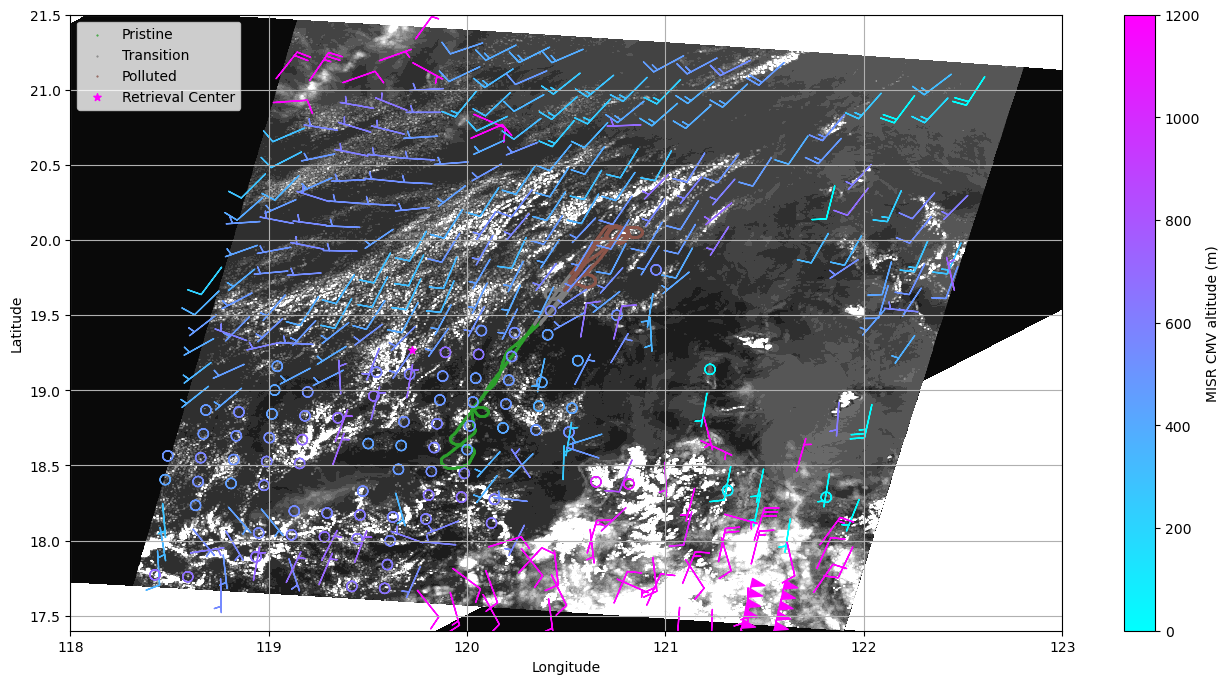

In [5]:
f, ax = plt.subplots(1, 1, figsize=(16,8))

# Plot MISR BRF
ax.contourf(obs.lon275.data, obs.lat275.data, obs.brf.isel(camera=4).data, vmin=0, vmax=0.20, cmap='gray', levels=100)

# Plot MISR CTH
# levels = np.arange(0, 1500, 100)
# cth_ax = ax.contourf(cth.lon1100.data, cth.lat1100.data, cth.cth.data, alpha=1.0, vmin=0, vmax=1400, levels=levels, cmap=cth_cmap)
# plt.colorbar(cth_ax, label='Cloud Top Height (m)')

# Plot MISR aerosols
# as_lon = np.ravel(aerosol_ds.Longitude.data)
# as_lat = np.ravel(aerosol_ds.Latitude.data)
# aod = ax.scatter(as_lon, as_lat, c=aerosol_ds.aod670.data, s=13, alpha=1.0, marker='s', vmin=None, vmax=None, cmap=aod_cmap)
# plt.colorbar(aod, label='670 nm aod')

# Plot MISR aerosol lowest residual mixture
# as_lon = np.ravel(aerosol_ds.Longitude.data)
# as_lat = np.ravel(aerosol_ds.Latitude.data)
# aersol_lrm_ax = ax.scatter(as_lon, as_lat, c=aerosol_ds.Lowest_Residual_Mixture.data, s=13, alpha=1.0, marker='s', vmin=None, vmax=None, cmap=aerosol_lrm_cmap)
# plt.colorbar(aersol_lrm_ax, label='Lowest Residual Mixture')

# Plot P3 Flight tracks
p3track_size = 0.25
ax.scatter(p3.Longitude.data[pristine], p3.Latitude.data[pristine], s=p3track_size, c=prist_color, label='Pristine')
ax.scatter(p3.Longitude.data[trans], p3.Latitude.data[trans], s=p3track_size, c=trans_color, label='Transition')
ax.scatter(p3.Longitude.data[polluted], p3.Latitude.data[polluted], s=p3track_size, c=poll_color, label='Polluted')

# Plot SPEC samples
# spec_re = ax.scatter(p3.Longitude.data, p3.Latitude.data, s=7, alpha=1.0, c=p3.Reff_um.data, cmap='cividis')
# plt.colorbar(spec_re, label='Reff (um)')

# Plot ERA5 wind barbs
# 10 m winds
# ax.barbs(era_surf.longitude, era_surf.latitude, era_surf.u10*1.94384, era_surf.v10*1.94384, barbcolor='tab:orange', label='ERA5 10 m winds')
# 100 m winds
# ax.barbs(era_surf.longitude, era_surf.latitude, era_surf.u100*1.94384, era_surf.v100*1.94384, barbcolor='tab:red', label='ERA5 100 m winds')
# 1000 hpa winds
# era1000hpa_ax = ax.barbs(era_1000hpa.longitude, era_1000hpa.latitude, era_1000hpa.u*1.94384, era_1000hpa.v*1.94384, era_1000hpa.z, label='ERA5 1000 hpa winds', cmap=era5_cmap)
# plt.colorbar(era1000hpa_ax, label='era5 wind barb altitude (m)')

# Plot MISR CMV wind barbs
misr_cmv_ax = ax.barbs(misr_cmv.lon17600, misr_cmv.lat17600, misr_cmv.cmv_E*1.94384, misr_cmv.cmv_N*1.94384, misr_cmv.cth_motion, clim=(0, 1200), cmap=misr_cmv_cmap)
plt.colorbar(misr_cmv_ax, label='MISR CMV altitude (m)')

# Plot AT3D retreival center & sampling points
ax.scatter(target_lon, target_lat, marker='*', c=target_color, s=30, label='Retrieval Center')
# ax.scatter(obs.lon17600.data, obs.lat17600, s=3, c='tab:red')

# Adjust window
ax.set_xlim(lon_window)
ax.set_ylim(lat_window)
ax.grid()
ax.legend(loc='upper left')
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')

## Cloud Top Height

In [6]:
def plot_box(ll, ur, f, ax, c='r'):
    ax.plot([ll[0], ur[0]], [ll[1], ll[1]], c=c) # lower line
    ax.plot([ll[0], ur[0]], [ur[1], ur[1]], c=c) # upper line
    ax.vlines([ll[0], ur[0]], ll[1], ur[1], colors=c) # vert lines

In [7]:
lcl = 400

Text(0.5, 1.0, 'Whole Scene')

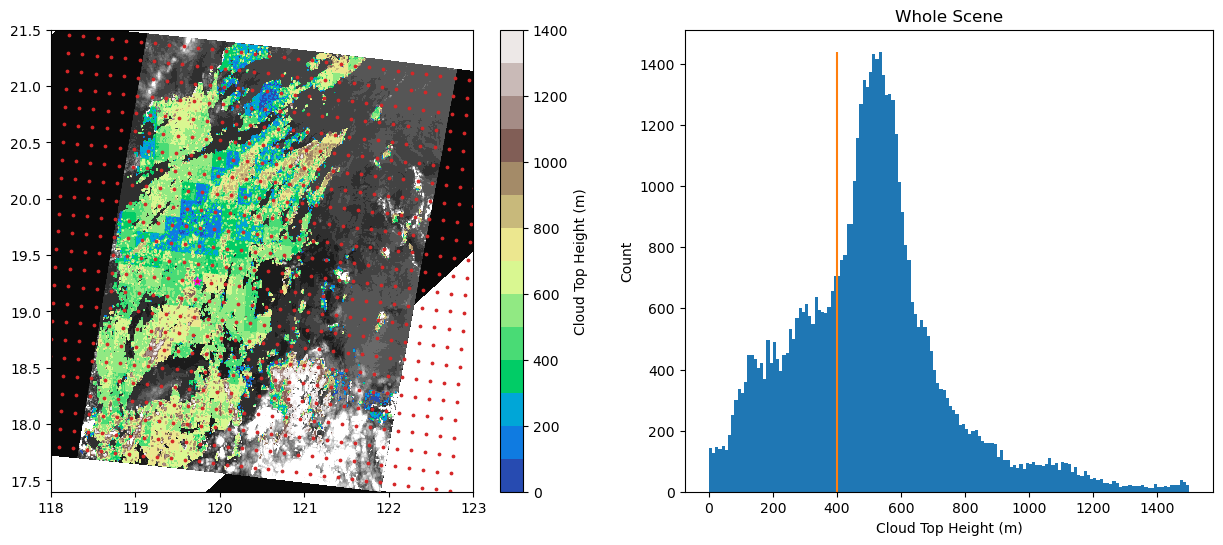

In [8]:
f, ax = plt.subplots(1, 2, figsize=(15,6))

# Plot MISR BRF
ax[0].contourf(obs.lon275.data, obs.lat275.data, obs.brf.isel(camera=4).data, vmin=0, vmax=0.20, cmap='gray', levels=100)
ax[0].set_xlim(lon_window)
ax[0].set_ylim(lat_window)

# Plot MISR CTH
levels = np.arange(0, 1500, 100)
cth_ax = ax[0].contourf(cth.lon1100.data, cth.lat1100.data, cth.cth.data, alpha=1.0, vmin=0, vmax=1400, levels=levels, cmap=cth_cmap)
plt.colorbar(cth_ax, ax=ax[0], label='Cloud Top Height (m)')

# Plot AT3D retreival center & sampling points
ax[0].scatter(target_lon, target_lat, marker='*', c=target_color, s=30, label='Retrieval Center')
ax[0].scatter(obs.lon17600.data, obs.lat17600, s=3, c='tab:red')

bins = np.arange(-1, 1501, 10) + 0.5
h = ax[1].hist(np.ravel(cth.cth.data), bins=bins)
ax[1].vlines(lcl, 0, np.max(h[0]), colors='tab:orange')
ax[1].set_xlabel('Cloud Top Height (m)')
ax[1].set_ylabel('Count')
ax[1].set_title('Whole Scene')
# print(h[1])

In [9]:
# Subset conditions
lon_range = 0.1
lat_range = 0.08
ll = [target_lon-lon_range, target_lat-lat_range]
ur = [target_lon+lon_range, target_lat+lat_range]
lon_cond = (cth.lon1100.data > ll[0]) & (cth.lon1100.data < ur[0])
lat_cond = (cth.lat1100.data > ll[1]) & (cth.lat1100.data < ur[1])
sub_cond = lon_cond & lat_cond

lon_pad = 1.5
lat_pad = 1.5

Text(0.5, 1.0, 'Sub Scene')

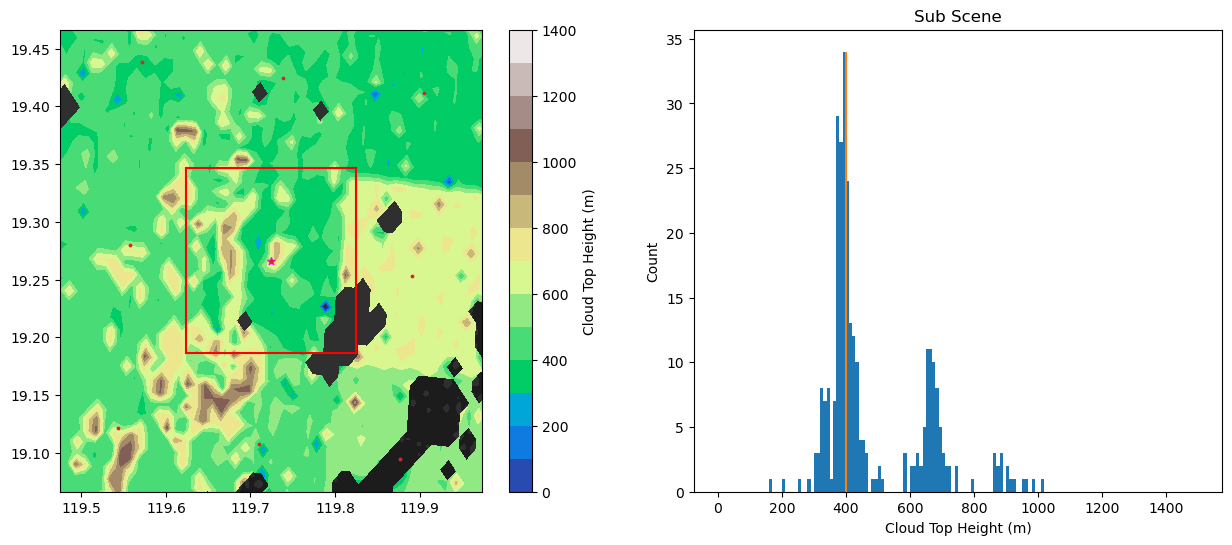

In [10]:
f, ax = plt.subplots(1, 2, figsize=(15,6))

# Plot MISR BRF
ax[0].contourf(obs.lon275.data, obs.lat275.data, obs.brf.isel(camera=4).data, vmin=0, vmax=0.20, cmap='gray', levels=100)
ax[0].set_xlim([ll[0] - lon_pad*lon_range, ur[0] + lon_pad*lon_range])
ax[0].set_ylim([ll[1] - lat_pad*lat_range, ur[1] + lat_pad*lat_range])

# Plot MISR CTH
levels = np.arange(0, 1500, 100)
cth_ax = ax[0].contourf(cth.lon1100.data, cth.lat1100.data, cth.cth.data, alpha=1.0, vmin=0, vmax=1400, levels=levels, cmap=cth_cmap)
plt.colorbar(cth_ax, ax=ax[0], label='Cloud Top Height (m)')

plot_box(ll, ur, f, ax[0], c='r')

# Plot AT3D retreival center & sampling points
ax[0].scatter(target_lon, target_lat, marker='*', c=target_color, s=30, label='Retrieval Center')
ax[0].scatter(obs.lon17600.data, obs.lat17600, s=3, c='tab:red')

bins = np.arange(-1, 1501, 10) + 0.5
h = ax[1].hist(np.ravel(cth.cth.data[sub_cond]), bins=bins)
ax[1].vlines(lcl, 0, np.max(h[0]), colors='tab:orange')
ax[1].set_xlabel('Cloud Top Height (m)')
ax[1].set_ylabel('Count')
ax[1].set_title('Sub Scene')
# print(h[1])

Text(0.5, 1.0, 'Stereo Opacity Bias Adjusted Sub Scene')

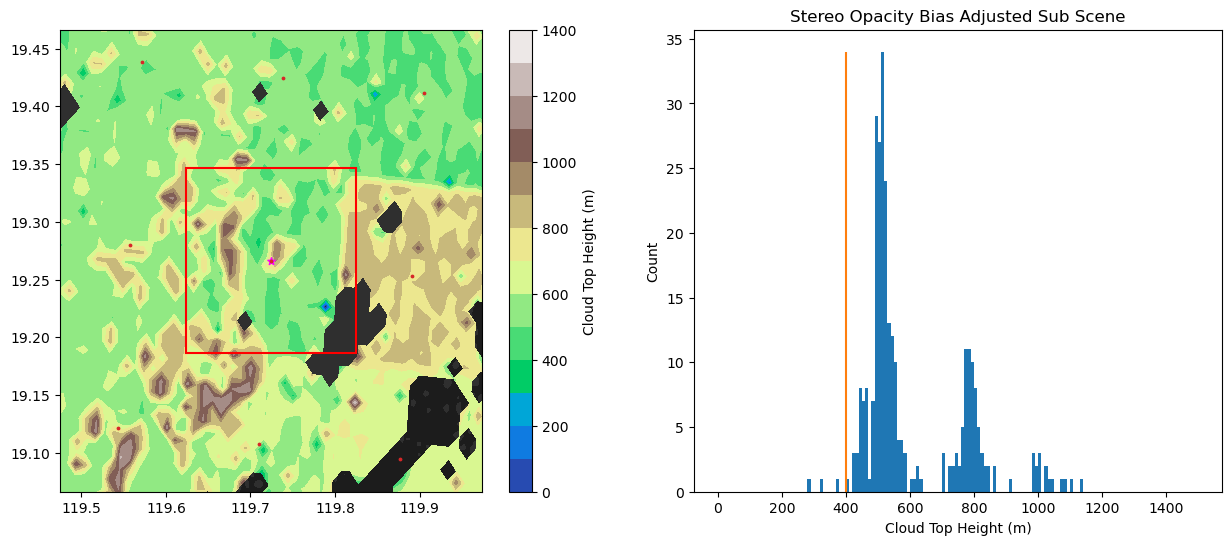

In [11]:
## Stereo Opacity Bias Adjusted
opacity_bias = 120 # m

f, ax = plt.subplots(1, 2, figsize=(15,6))

# Plot MISR BRF
ax[0].contourf(obs.lon275.data, obs.lat275.data, obs.brf.isel(camera=4).data, vmin=0, vmax=0.20, cmap='gray', levels=100)
ax[0].set_xlim([ll[0] - lon_pad*lon_range, ur[0] + lon_pad*lon_range])
ax[0].set_ylim([ll[1] - lat_pad*lat_range, ur[1] + lat_pad*lat_range])

# Plot MISR CTH
levels = np.arange(0, 1500, 100)
cth_ax = ax[0].contourf(cth.lon1100.data, cth.lat1100.data, cth.cth.data+opacity_bias, alpha=1.0, vmin=0, vmax=1400, levels=levels, cmap=cth_cmap)
plt.colorbar(cth_ax, ax=ax[0], label='Cloud Top Height (m)')

plot_box(ll, ur, f, ax[0], c='r')

# Plot AT3D retreival center & sampling points
ax[0].scatter(target_lon, target_lat, marker='*', c=target_color, s=30, label='Retrieval Center')
ax[0].scatter(obs.lon17600.data, obs.lat17600, s=3, c='tab:red')

bins = np.arange(-1, 1501, 10) + 0.5
h = ax[1].hist(np.ravel(cth.cth.data[sub_cond] + opacity_bias), bins=bins)
ax[1].vlines(lcl, 0, np.max(h[0]), colors='tab:orange')
ax[1].set_xlabel('Cloud Top Height (m)')
ax[1].set_ylabel('Count')
ax[1].set_title('Stereo Opacity Bias Adjusted Sub Scene')
# print(h[1])

## Surface Winds

In [12]:
era_surf_point = era_surf.interp(latitude=target_lat, longitude=target_lon, method='linear')
print('10 meter winds at target({:.3f}, {:.3f}):'.format(target_lat, target_lon))
print('   u  = {:.3f} m/s'.format(era_surf_point.u10.data))
print('   v  = {:.3f} m/s'.format(era_surf_point.v10.data))
print('  |s| = {:.3f} m/s'.format((era_surf_point.u10.data**2 + era_surf_point.v10.data**2)**0.5))

print('100 meter winds at target ({:.3f}, {:.3f}):'.format(target_lat, target_lon))
print('   u  = {:.3f} m/s'.format(era_surf_point.u100.data))
print('   v  = {:.3f} m/s'.format(era_surf_point.v100.data))
print('  |s| = {:.3f} m/s'.format((era_surf_point.u100.data**2 + era_surf_point.v100.data**2)**0.5))

10 meter winds at target(19.266, 119.724):
   u  = 0.557 m/s
   v  = 0.373 m/s
  |s| = 0.670 m/s
100 meter winds at target (19.266, 119.724):
   u  = 0.570 m/s
   v  = 0.382 m/s
  |s| = 0.686 m/s


## Upper level winds

### MISR Cloud Motion Vectors

In [13]:
target_cond = (misr_cmv.lat17600.data == target_lat) & (misr_cmv.lon17600.data == target_lon)
assert np.sum(target_cond == 1)
target_cth_motion = misr_cmv.cth_motion.data[target_cond][0]
target_cmv_E = misr_cmv.cmv_E.data[target_cond][0]
target_cmv_N = misr_cmv.cmv_N.data[target_cond][0]

print('MISR CMV at target ({:.3f}, {:.3f})'.format(target_lat, target_lon))
print('   Height of Motion = {:.3f} m'.format(target_cth_motion))
print('   CMV East = {:.3f}'.format(target_cmv_E))
print('   CMV North = {:.3f}'.format(target_cmv_N))
print('   CMV Speed = {:.3f}'.format((target_cmv_E**2 + target_cmv_N**2)**0.5))
print('   CMV Direction = {:.3f} degrees from north going counterclockwise'.format(np.degrees(np.arctan2(target_cmv_E, target_cmv_N))))

MISR CMV at target (19.266, 119.724)
   Height of Motion = 541.426 m
   CMV East = 1.355
   CMV North = 1.949
   CMV Speed = 2.374
   CMV Direction = 34.806 degrees from north going counterclockwise


Average of n = 6 CMVs between 491.4 m and 591.4 m:
   Average CMV East = 0.90 m/s
   Average CMV North = 1.15 m/s
   (Maen_CMV_E**2 + Mean_CMV_N**2)**0.5 = 1.46 m/s
   Average CMV Speed = 1.50 m/s


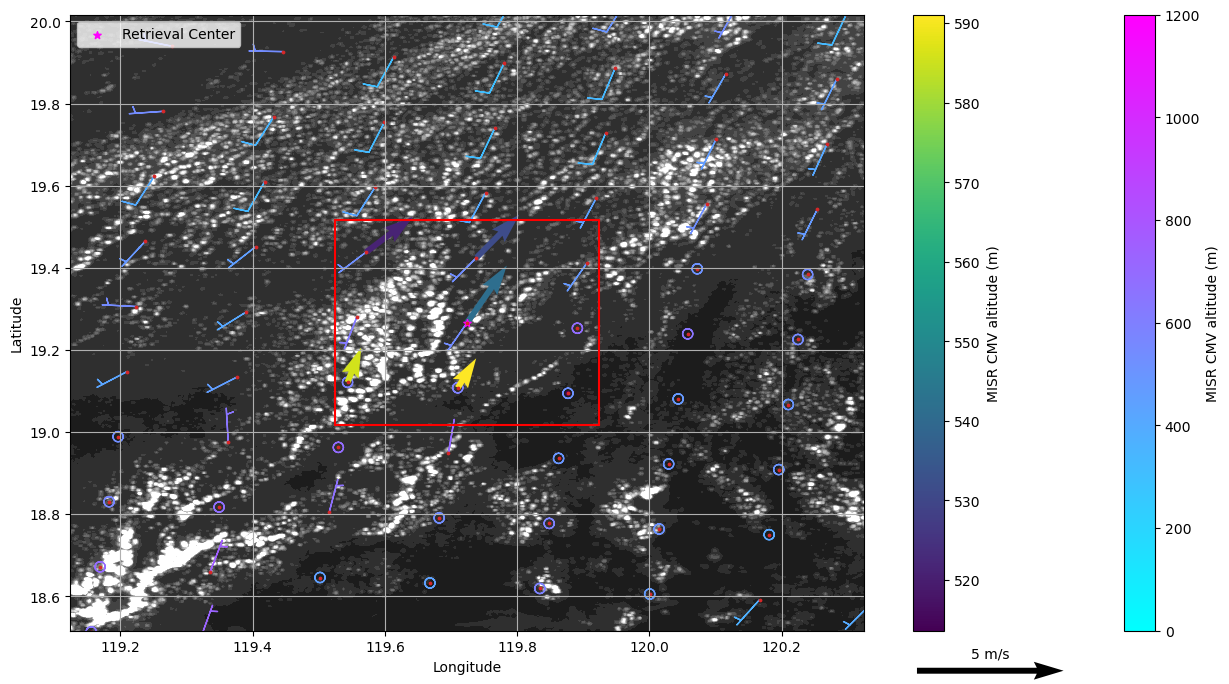

In [14]:
# lon_range = 0.53
# lat_range = 0.6
lon_range = 0.2
lat_range = 0.25
ll = [target_lon-lon_range, target_lat-lat_range]
ur = [target_lon+lon_range, target_lat+lat_range]
lon_cond = (misr_cmv.lon17600.data > ll[0]) & (misr_cmv.lon17600.data < ur[0])
lat_cond = (misr_cmv.lat17600.data > ll[1]) & (misr_cmv.lat17600.data < ur[1])
sub_cond = lon_cond & lat_cond

lon_pad = 2.0
lat_pad = 2.0

bin_size = 100
cth_window = [target_cth_motion - 0.5*bin_size, target_cth_motion + 0.5*bin_size]
cth_cond = (misr_cmv.cth_motion.data > cth_window[0]) & (misr_cmv.cth_motion.data < cth_window[1]) & lat_cond & lon_cond

f, ax = plt.subplots(1, 1, figsize=(16,8))

# Plot MISR BRF
ax.contourf(obs.lon275.data, obs.lat275.data, obs.brf.isel(camera=4).data, vmin=0, vmax=0.20, cmap='gray', levels=100)

# Plot MISR CMV wind barbs
# misr_cmv_ax = ax.barbs(misr_cmv.lon17600.data[cth_cond], misr_cmv.lat17600.data[cth_cond], misr_cmv.cmv_E.data[cth_cond]*1.94384, misr_cmv.cmv_N.data[cth_cond]*1.94384, misr_cmv.cth_motion.data[cth_cond], cmap=misr_cmv_cmap)
misr_cmv_ax = ax.barbs(misr_cmv.lon17600.data, misr_cmv.lat17600.data, misr_cmv.cmv_E.data*1.94384, misr_cmv.cmv_N.data*1.94384, misr_cmv.cth_motion.data, clim=(0, 1200), cmap=misr_cmv_cmap)
plt.colorbar(misr_cmv_ax, label='MISR CMV altitude (m)')

# Plot MISR CMV quivers
misr_cmv_ax = ax.quiver(misr_cmv.lon17600.data[cth_cond], misr_cmv.lat17600.data[cth_cond], misr_cmv.cmv_E.data[cth_cond], misr_cmv.cmv_N.data[cth_cond], misr_cmv.cth_motion.data[cth_cond], units='xy')
# misr_cmv_ax = ax.quiver(misr_cmv.lon17600.data, misr_cmv.lat17600.data, misr_cmv.cmv_E.data, misr_cmv.cmv_N.data, misr_cmv.cth_motion.data, units='xy')
ax.quiverkey(misr_cmv_ax, 0.7, 0.06, 5, '5 m/s', labelpos='N', coordinates='figure')
plt.colorbar(misr_cmv_ax, label='MISR CMV altitude (m)')

# Plot AT3D retreival center & sampling points
ax.scatter(target_lon, target_lat, marker='*', c=target_color, s=30, label='Retrieval Center')
ax.scatter(obs.lon17600.data, obs.lat17600, s=3, c='tab:red')

plot_box(ll, ur, f, ax, c='r')

# Adjust window
ax.set_xlim([ll[0] - lon_pad*lon_range, ur[0] + lon_pad*lon_range])
ax.set_ylim([ll[1] - lat_pad*lat_range, ur[1] + lat_pad*lat_range])
# ax.set_xlim(lon_window)
# ax.set_ylim(lat_window)
ax.grid()
ax.legend(loc='upper left')
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')

print('Average of n = {} CMVs between {:.1f} m and {:.1f} m:'.format(np.sum(cth_cond), cth_window[0], cth_window[1]))
mean_E = np.nanmean(misr_cmv.cmv_E.data[cth_cond])
mean_N = np.nanmean(misr_cmv.cmv_N.data[cth_cond])
print('   Average CMV East = {:.2f} m/s'.format(mean_E))
print('   Average CMV North = {:.2f} m/s'.format(mean_N))
print('   (Maen_CMV_E**2 + Mean_CMV_N**2)**0.5 = {:.2f} m/s'.format((mean_E**2 + mean_N**2)**0.5))
print('   Average CMV Speed = {:.2f} m/s'.format(np.nanmean((misr_cmv.cmv_E.data[cth_cond]**2 + misr_cmv.cmv_N.data[cth_cond]**2)**0.5)))

## Aerosol

Text(0, 0.5, 'Latitude')

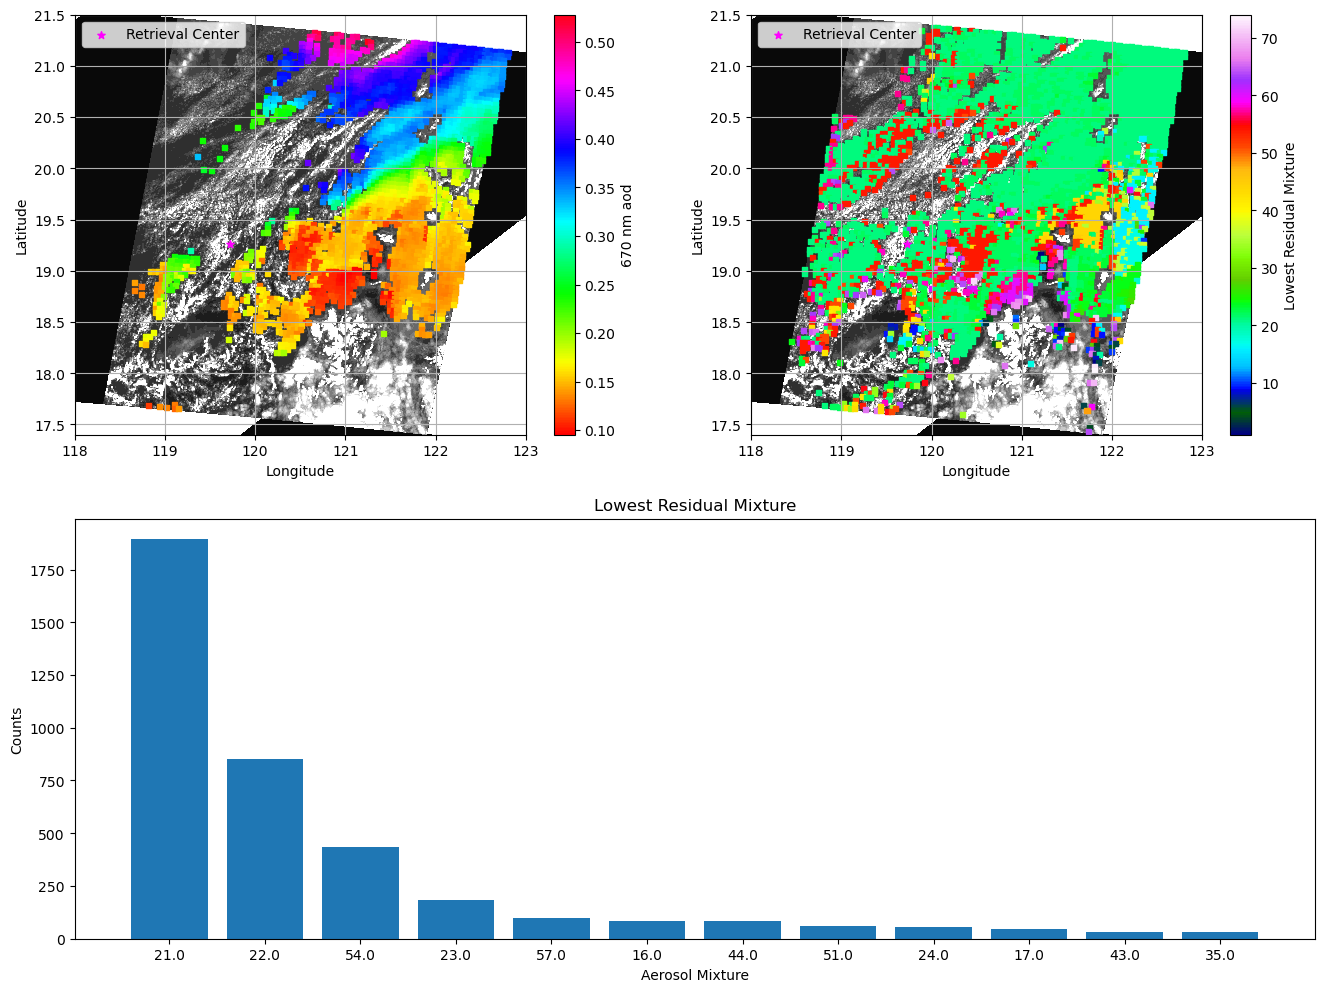

In [15]:
f = plt.figure(figsize=(16,12))

gs = GridSpec(2, 2, figure=f)
ax00 = f.add_subplot(gs[0,0])
ax01 = f.add_subplot(gs[0,1])
ax1 = f.add_subplot(gs[1,:])

# Plot MISR BRF
ax00.contourf(obs.lon275.data, obs.lat275.data, obs.brf.isel(camera=4).data, vmin=0, vmax=0.20, cmap='gray', levels=100)
ax01.contourf(obs.lon275.data, obs.lat275.data, obs.brf.isel(camera=4).data, vmin=0, vmax=0.20, cmap='gray', levels=100)

# Plot MISR aerosols
as_lon = np.ravel(aerosol_ds.Longitude.data)
as_lat = np.ravel(aerosol_ds.Latitude.data)
aod = ax00.scatter(as_lon, as_lat, c=aerosol_ds.aod670.data, s=13, alpha=1.0, marker='s', vmin=None, vmax=None, cmap=aod_cmap)
plt.colorbar(aod, label='670 nm aod')

# Plot MISR aerosol lowest residual mixture
as_lon = np.ravel(aerosol_ds.Longitude.data)
as_lat = np.ravel(aerosol_ds.Latitude.data)
aersol_lrm_ax = ax01.scatter(as_lon, as_lat, c=aerosol_ds.Lowest_Residual_Mixture.data, s=13, alpha=1.0, marker='s', vmin=None, vmax=None, cmap=aerosol_lrm_cmap)
plt.colorbar(aersol_lrm_ax, label='Lowest Residual Mixture')

# Aerosol lowest residual mixture bars
n_mixtures = 12
hist, bin_edges = np.histogram(aerosol_ds.Lowest_Residual_Mixture.data, bins=74, range=(0.5, 74.5))
midpoints = (bin_edges[:-1] + bin_edges[1:])/2
sorted_hist = np.sort(hist)
sorted_hist = sorted_hist[::-1]
sorted_midpoints = midpoints[np.argsort(hist)]
sorted_midpoints = sorted_midpoints[::-1]
ax1.bar(sorted_midpoints.astype('str')[:n_mixtures], sorted_hist[:n_mixtures])
ax1.set_xlabel('Aerosol Mixture')
ax1.set_ylabel('Counts')
ax1.set_title('Lowest Residual Mixture')

# Plot AT3D retreival center & sampling points
ax00.scatter(target_lon, target_lat, marker='*', c=target_color, s=30, label='Retrieval Center')
ax01.scatter(target_lon, target_lat, marker='*', c=target_color, s=30, label='Retrieval Center')
# ax00.scatter(obs.lon17600.data, obs.lat17600, s=3, c='tab:red')
# ax01.scatter(obs.lon17600.data, obs.lat17600, s=3, c='tab:red')

# Adjust window
ax00.set_xlim(lon_window)
ax00.set_ylim(lat_window)
ax00.grid()
ax00.legend(loc='upper left')
ax00.set_xlabel('Longitude')
ax00.set_ylabel('Latitude')
ax01.set_xlim(lon_window)
ax01.set_ylim(lat_window)
ax01.grid()
ax01.legend(loc='upper left')
ax01.set_xlabel('Longitude')
ax01.set_ylabel('Latitude')

Text(0, 0.5, 'Latitude')

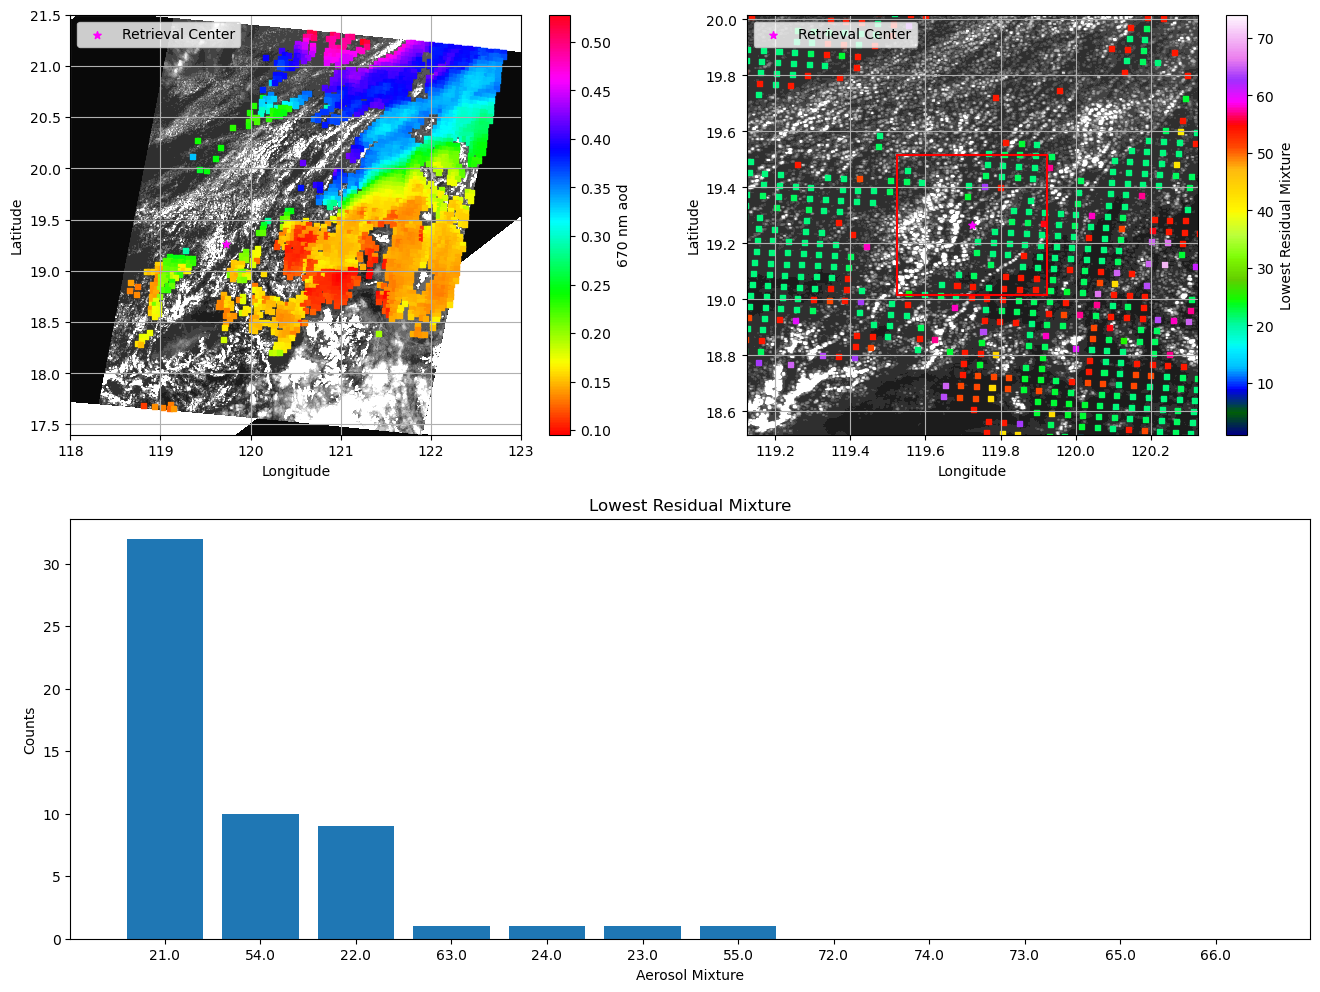

In [16]:
# lon_range = 0.53
# lat_range = 0.6
lon_range = 0.2
lat_range = 0.25
ll = [target_lon-lon_range, target_lat-lat_range]
ur = [target_lon+lon_range, target_lat+lat_range]
lon_cond = (aerosol_ds.Longitude.data > ll[0]) & (aerosol_ds.Longitude.data < ur[0])
lat_cond = (aerosol_ds.Latitude.data > ll[1]) & (aerosol_ds.Latitude.data < ur[1])
sub_cond = lon_cond & lat_cond

lon_pad = 2.0
lat_pad = 2.0

f = plt.figure(figsize=(16,12))

gs = GridSpec(2, 2, figure=f)
ax00 = f.add_subplot(gs[0,0])
ax01 = f.add_subplot(gs[0,1])
ax1 = f.add_subplot(gs[1,:])

# Plot MISR BRF
ax00.contourf(obs.lon275.data, obs.lat275.data, obs.brf.isel(camera=4).data, vmin=0, vmax=0.20, cmap='gray', levels=100)
ax01.contourf(obs.lon275.data, obs.lat275.data, obs.brf.isel(camera=4).data, vmin=0, vmax=0.20, cmap='gray', levels=100)

# Plot MISR aerosols
as_lon = np.ravel(aerosol_ds.Longitude.data)
as_lat = np.ravel(aerosol_ds.Latitude.data)
aod = ax00.scatter(as_lon, as_lat, c=aerosol_ds.aod670.data, s=13, alpha=1.0, marker='s', vmin=None, vmax=None, cmap=aod_cmap)
plt.colorbar(aod, label='670 nm aod')

# Plot MISR aerosol lowest residual mixture
as_lon = np.ravel(aerosol_ds.Longitude.data)
as_lat = np.ravel(aerosol_ds.Latitude.data)
aersol_lrm_ax = ax01.scatter(as_lon, as_lat, c=aerosol_ds.Lowest_Residual_Mixture.data, s=13, alpha=1.0, marker='s', vmin=None, vmax=None, cmap=aerosol_lrm_cmap)
plt.colorbar(aersol_lrm_ax, label='Lowest Residual Mixture')
plot_box(ll, ur, f, ax01, c='r')
# ax01.set_xlim(lon_window)
# ax01.set_ylim(lat_window)
ax01.set_xlim([ll[0] - lon_pad*lon_range, ur[0] + lon_pad*lon_range])
ax01.set_ylim([ll[1] - lat_pad*lat_range, ur[1] + lat_pad*lat_range])
ax01.grid()
ax01.set_xlabel('Longitude')
ax01.set_ylabel('Latitude')

# Aerosol lowest residual mixture bars
n_mixtures = 12
hist, bin_edges = np.histogram(aerosol_ds.Lowest_Residual_Mixture.data[sub_cond], bins=74, range=(0.5, 74.5))
midpoints = (bin_edges[:-1] + bin_edges[1:])/2
sorted_hist = np.sort(hist)
sorted_hist = sorted_hist[::-1]
sorted_midpoints = midpoints[np.argsort(hist)]
sorted_midpoints = sorted_midpoints[::-1]
ax1.bar(sorted_midpoints.astype('str')[:n_mixtures], sorted_hist[:n_mixtures])
ax1.set_xlabel('Aerosol Mixture')
ax1.set_ylabel('Counts')
ax1.set_title('Lowest Residual Mixture')

# Plot AT3D retreival center & sampling points
ax00.scatter(target_lon, target_lat, marker='*', c=target_color, s=30, label='Retrieval Center')
ax01.scatter(target_lon, target_lat, marker='*', c=target_color, s=30, label='Retrieval Center')
# ax00.scatter(obs.lon17600.data, obs.lat17600, s=3, c='tab:red')
# ax01.scatter(obs.lon17600.data, obs.lat17600, s=3, c='tab:red')

# Adjust window
ax00.set_xlim(lon_window)
ax00.set_ylim(lat_window)
ax00.grid()
ax00.legend(loc='upper left')
ax01.legend(loc='upper left')
ax00.set_xlabel('Longitude')
ax00.set_ylabel('Latitude')

## P3

Text(0, 0.5, 'altitude (m)')

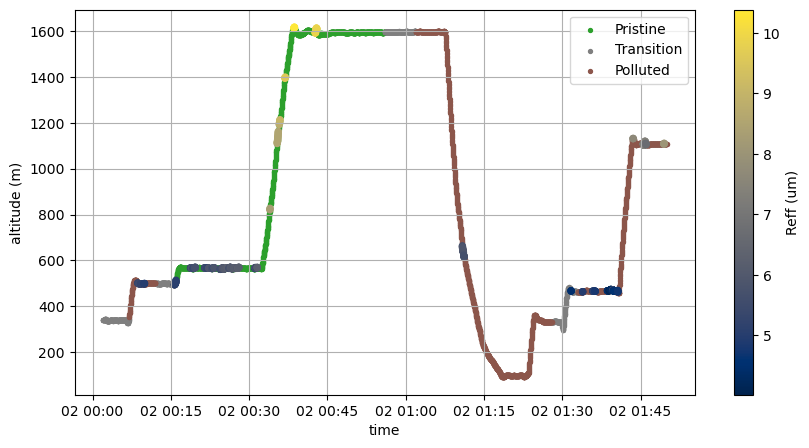

In [17]:
# Plot P3 altitude vs time
f, ax = plt.subplots(1, 1, figsize=(10,5))
size = 8
ax.scatter(p3.time.data[pristine], p3.GPS_Altitude.data[pristine], s=size, c=prist_color, label='Pristine')
ax.scatter(p3.time.data[trans], p3.GPS_Altitude.data[trans], s=size, c=trans_color, label='Transition')
ax.scatter(p3.time.data[polluted], p3.GPS_Altitude.data[polluted], s=size, c=poll_color, label='Polluted')
p3_reff = ax.scatter(p3.time.data, p3.GPS_Altitude.data, s=size+11, c=p3.Reff_um.data, cmap='cividis')
plt.colorbar(p3_reff, ax=ax, label='Reff (um)')
ax.legend()
ax.grid()
ax.set_xlabel('time')
ax.set_ylabel('altitude (m)')

In [18]:
def ReffLinearRegression(p3):
    # Prepare the data
    y = p3['Reff_um'].data
    cloud_cond = ~np.isnan(y)
    y_cloud = y[cloud_cond]
    y_pris = y[cloud_cond & pristine]
    y_poll = y[cloud_cond & polluted]
    X = p3['GPS_Altitude'].data / 1000
    X_cloud = X[cloud_cond].reshape(-1, 1)
    X_pris = X[cloud_cond & pristine].reshape(-1, 1)
    X_poll = X[cloud_cond & polluted].reshape(-1, 1)

    # Create an instance of the LinearRegression model
    m_cloud = LinearRegression()
    m_pris = LinearRegression()
    m_poll = LinearRegression()

    # Fit the model to the data
    m_cloud.fit(X_cloud, y_cloud)
    m_pris.fit(X_pris, y_pris)
    m_poll.fit(X_poll, y_poll)

    # Print the regression results
    print('All Cloud:')
    print("   Intercept:", m_cloud.intercept_)
    print("   Coefficient:", m_cloud.coef_)
    print('Pristine:')
    print("   Intercept:", m_pris.intercept_)
    print("   Coefficient:", m_pris.coef_)
    print('All Cloud:')
    print("   Intercept:", m_poll.intercept_)
    print("   Coefficient:", m_poll.coef_)

    return m_cloud, m_pris, m_poll

All Cloud:
   Intercept: 2.991867942556189
   Coefficient: [4.41088483]
Pristine:
   Intercept: 3.4640699891784057
   Coefficient: [4.21285275]
All Cloud:
   Intercept: 2.6225217705851955
   Coefficient: [4.29198287]


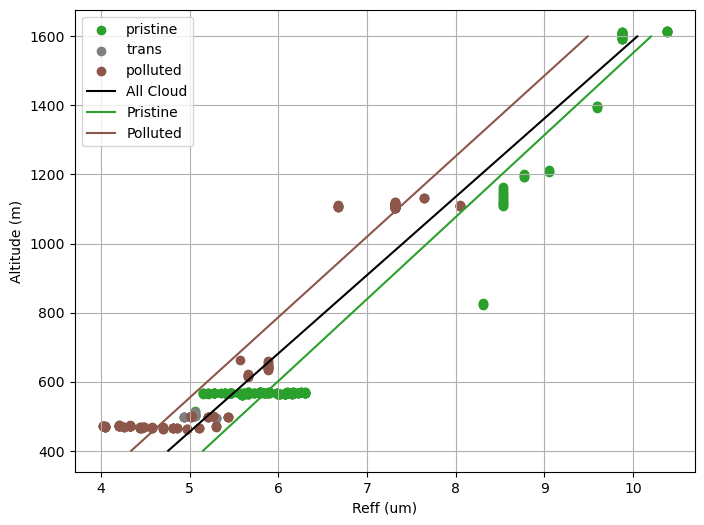

In [19]:
m_cloud, m_pris, m_poll = ReffLinearRegression(p3)

# Plot effective radius vs altitude
f, ax = plt.subplots(1, 1, figsize=(8, 6))
ax.scatter(p3.Reff_um.data[pristine], p3.GPS_Altitude[pristine], c=prist_color, label='pristine')
ax.scatter(p3.Reff_um.data[trans], p3.GPS_Altitude[trans], c=trans_color, label='trans')
ax.scatter(p3.Reff_um.data[polluted], p3.GPS_Altitude[polluted], c=poll_color, label='polluted')

z = np.linspace(400, 1600, 200)
re_cloud = m_cloud.intercept_ + m_cloud.coef_ * z/1000
re_pris = m_pris.intercept_ + m_pris.coef_ * z/1000
re_poll = m_poll.intercept_ + m_poll.coef_ * z/1000

ax.plot(re_cloud, z, color='black', label='All Cloud')
ax.plot(re_pris, z, color=prist_color, label='Pristine')
ax.plot(re_poll, z, color=poll_color, label='Polluted')
ax.set_xlabel('Reff (um)')
ax.set_ylabel('Altitude (m)')
ax.grid()
ax.legend()


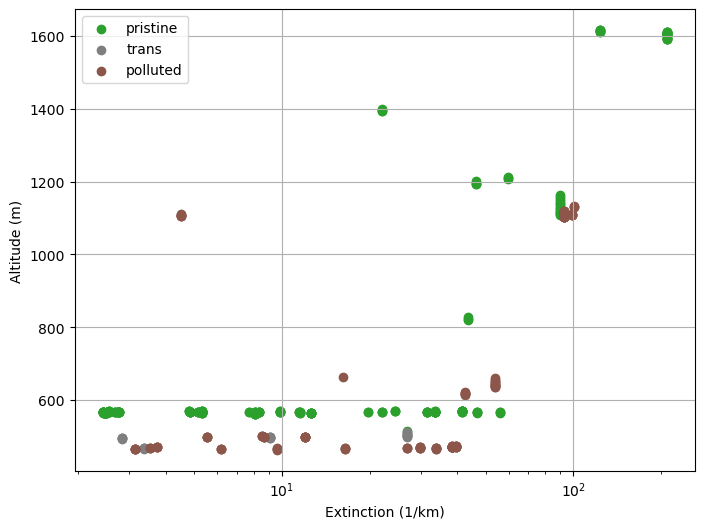

In [20]:
# Plot extinction vs altitude
f, ax = plt.subplots(1, 1, figsize=(8, 6))
ax.scatter(p3.ext_km.data[pristine], p3.GPS_Altitude[pristine], c=prist_color, label='pristine')
ax.scatter(p3.ext_km.data[trans], p3.GPS_Altitude[trans], c=trans_color, label='trans')
ax.scatter(p3.ext_km.data[polluted], p3.GPS_Altitude[polluted], c=poll_color, label='polluted')

ax.set_xlabel('Extinction (1/km)')
ax.set_ylabel('Altitude (m)')
ax.grid()
ax.legend()
ax.set_xscale('log')
